# Las Taperas — DeepForest y Mask R-CNN

## 1. Preparación compartida

In [ ]:
%pip -q install deepforest rasterio ultralytics geopandas pyogrio shapely matplotlib pandas tqdm scipy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires safetensors>=0.8.0, but you have safetensors 0.5.3 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window
from rasterio.enums import ColorInterp, Resampling, MaskFlags
from rasterio.features import rasterize, shapes
from shapely.geometry import box, shape
from matplotlib.lines import Line2D
from tqdm.auto import tqdm

SITIO = 'Las Taperas'
ROOT = Path('/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal')
PROYECTO = ROOT.parent
DATOS = ROOT / 'datos'
RASTER = DATOS / 'Las_Taperas_Pot2_Clip.tif'
CENSO = DATOS / 'Censo_LasTaperas_002_parcelas_41_42_43_44_45.shp'
PREDIO = DATOS / 'Area_Censada_LasTaperas.gpkg'

print("Predio:", SITIO)
print("Ortofoto:", RASTER)
print("Censo:", CENSO)
# Archivos compartidos por ambos modelos.
SALIDA_COMUN = ROOT / 'resultados' / 'Las_Taperas' / 'compartido'
SALIDA_COMUN.mkdir(parents=True, exist_ok=True)
MASCARA_COMUN = SALIDA_COMUN / 'mascara_evaluable.tif'


Predio: Las Taperas
Ortofoto: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Las_Taperas_Pot2_Clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_LasTaperas_002_parcelas_41_42_43_44_45.shp


## 2. Máscara y censo evaluable

La misma área evaluable se utiliza para los dos modelos.

In [ ]:
MASCARA = MASCARA_COMUN
with rasterio.open(RASTER) as src:
    assert src.crs is not None and src.count >= 3
    alpha_bands = [i+1 for i, ci in enumerate(src.colorinterp) if ci == ColorInterp.alpha]
    has_nodata = src.nodata is not None
    if not alpha_bands and not has_nodata:
        flags = src.mask_flag_enums[0]
        assert MaskFlags.all_valid not in flags, ('Revisar el TIFF')

    # Ajustar el polígono censado al sistema de coordenadas del raster.
    area = gpd.read_file(PREDIO)
    assert not area.empty and area.crs is not None
    area = area.to_crs(src.crs)
    zona = area.geometry.union_all()
    print('Área estimada del predio (ha):', round(zona.area / 10000, 2))

    perfil = src.profile.copy()
    perfil.update(driver='GTiff', count=1, dtype='uint8', nodata=0, compress='deflate')
    valid_pixels = 0
    with rasterio.open(MASCARA_COMUN, 'w', **perfil) as dst:
        for _, win in tqdm(src.block_windows(1), desc='Creando máscara'):
            h,w = int(win.height),int(win.width)
            zona_pixel = rasterize(
                [(zona, 1)], out_shape=(h, w),
                transform=src.window_transform(win), fill=0, dtype='uint8'
            ).astype(bool)
            if not zona_pixel.any():
                dst.write(np.zeros((h, w), dtype='uint8'), 1, window=win)
                continue
            if alpha_bands:
                cubierta = src.read(alpha_bands[0], window=win)>0
            elif has_nodata:
                rgb = src.read([1,2,3],window=win).astype('float32')
                cubierta = np.all(~np.isclose(rgb,src.nodata),axis=0)
            else:
                cubierta = src.read_masks(1,window=win)>0
            v = (cubierta & zona_pixel).astype('uint8')
            valid_pixels += int(v.sum())
            dst.write(v, 1, window=win)
    print('Cobertura válida en máscara (% del raster):',round(100*valid_pixels/(src.width*src.height),2))


# Verificar si cada punto se encuentra dentro de la máscara evaluable.
def puntos_mascara(geoms, ruta):
    with rasterio.open(ruta) as m:
        result=[]
        for g in geoms:
            if g is None or g.is_empty:
                result.append(False);continue
            try: result.append(bool(next(m.sample([(g.x,g.y)]))[0] == 1))
            except Exception: result.append(False)
        return np.asarray(result,dtype=bool)

censo_total = gpd.read_file(CENSO).reset_index(drop=True)
assert censo_total.crs is not None
with rasterio.open(MASCARA_COMUN) as m:
    censo_total = censo_total.to_crs(m.crs)
censo_eval = censo_total.loc[puntos_mascara(censo_total.geometry,MASCARA_COMUN)].copy().reset_index(drop=True)
censo_eval['id_punto'] = np.arange(len(censo_eval))
assert len(censo_eval) > 0, 'No hay árboles evaluables: revisar CRS, censo y máscara.'
print('Censo total:',len(censo_total),'| Censo evaluable:',len(censo_eval),
      '| Excluidos:',len(censo_total)-len(censo_eval))

Área estimada del predio (ha): 45.22


Creando máscara: 0it [00:00, ?it/s]

Cobertura válida en máscara (% del raster): 12.16
Censo total: 6759 | Censo evaluable: 6746 | Excluidos: 13


In [ ]:
# Emparejamiento espacial 1:1 compartido por ambos modelos.
def evaluar_detecciones(pred_unicas, censo_eval, mascara):
    pred_eval = pred_unicas.to_crs(censo_eval.crs).copy().reset_index(drop=True)
    if len(pred_eval):
        dentro = puntos_mascara(pred_eval.geometry.centroid, mascara)
        pred_eval = pred_eval.loc[dentro].copy().reset_index(drop=True)
    pred_eval['id_pred'] = np.arange(len(pred_eval))
    ref = censo_eval.copy().reset_index(drop=True)

    if len(pred_eval):
        pares = gpd.sjoin(ref[['id_punto', 'geometry']],
                          pred_eval[['id_pred', 'geometry']],
                          how='inner', predicate='within')
    else:
        pares = pd.DataFrame(columns=['id_punto', 'id_pred'])

    coincidencias = []
    if len(pares):
        puntos = ref.set_index('id_punto').geometry
        centros = pred_eval.set_index('id_pred').geometry.centroid
        pares['distancia_m'] = [puntos.loc[int(i)].distance(centros.loc[int(j)])
                                for i, j in zip(pares.id_punto, pares.id_pred)]
        pares = pares.sort_values('distancia_m')
        usados_ref, usados_pred = set(), set()
        for fila in pares.itertuples():
            i, j = int(fila.id_punto), int(fila.id_pred)
            if i not in usados_ref and j not in usados_pred:
                usados_ref.add(i)
                usados_pred.add(j)
                coincidencias.append({'id_punto': i, 'id_pred': j,
                                      'distancia_m': float(fila.distancia_m)})

    TP = len(coincidencias)
    NR, NP = len(ref), len(pred_eval)
    FP, FN = NP - TP, NR - TP
    P = TP / NP if NP else 0.0
    R = TP / NR if NR else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    error = 100 * (NP - NR) / NR
    assert TP + FP == NP and TP + FN == NR
    metricas = dict(censo_total=len(censo_total), censo_evaluable=NR,
                    detecciones=NP, TP=TP, FP=FP, FN=FN, precision=P,
                    recall=R, F1=F1, error_conteo_pct=error,
                    error_absoluto_pct=abs(error))
    return ref, pred_eval, coincidencias, metricas


## 3. DeepForest

### Configuración

In [ ]:
SALIDA = ROOT / 'resultados' / 'Las_Taperas_DeepForest'
SALIDA.mkdir(parents=True, exist_ok=True)
MASCARA = MASCARA_COMUN
PREPARADA = SALIDA / 'rgb_uint8_global.tif'

PATCH_SIZE = 400
PATCH_OVERLAP = 0.30
SCORE_THRESHOLD = 0.15
IOU_THRESHOLD = 0.15

print('Sitio:', SITIO, '\nOrtofoto:', RASTER, '\nCenso:', CENSO, '\nSalida:', SALIDA)

Sitio: Las Taperas 
Ortofoto: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Las_Taperas_Pot2_Clip.tif 
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_LasTaperas_002_parcelas_41_42_43_44_45.shp 
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las_Taperas_DeepForest


### Preparación RGB e inferencia

In [ ]:
from deepforest import main

# Muestrear píxeles para estimar el rango de intensidades sin cargar toda la imagen.
rng = np.random.default_rng(42)
values = []
with rasterio.open(RASTER) as src:
    alpha_bands = [i+1 for i,ci in enumerate(src.colorinterp) if ci == ColorInterp.alpha]
    for _, win in tqdm(src.block_windows(1), desc='Muestreando percentiles'):
        data = src.read([1,2,3],window=win).astype('float32')
        if alpha_bands:
            vv = src.read(alpha_bands[0],window=win)>0
        elif src.nodata is not None:
            vv = np.all(~np.isclose(data,src.nodata),axis=0)
        else:
            vv = src.read_masks(1,window=win)>0
        # muestra máx. 300 píxeles por bloque, repartida sobre la imagen
        locations = np.flatnonzero(vv.ravel())
        if locations.size:
            pick = rng.choice(locations,size=min(300,locations.size),replace=False)
            values.append(data.reshape(3,-1)[:,pick].reshape(-1))
assert values,'No hay píxeles válidos para calcular percentiles'
sample = np.concatenate(values)
p2 = float(np.percentile(sample,2))
p98 = float(np.percentile(sample,98))
del sample,values
assert np.isfinite(p2) and np.isfinite(p98) and p98>p2, 'Percentiles inválidos'
print('P2 muestreado:',p2,'P98 muestreado:',p98)

# Aplicar la misma escala a toda la imagen y anular los píxeles no evaluables.
with rasterio.open(RASTER) as src, rasterio.open(MASCARA) as msk:
    perfil = src.profile.copy()
    perfil.update(driver='GTiff',count=3,dtype='uint8',nodata=0,compress='deflate')
    with rasterio.open(PREPARADA,'w',**perfil) as dst:
        for _, win in tqdm(src.block_windows(1),desc='Preparando uint8'):
            data = src.read([1,2,3],window=win).astype('float32')
            valid = msk.read(1,window=win)>0
            rgb8=(np.clip((data-p2)/(p98-p2),0,1)*255).astype('uint8')
            rgb8[:,~valid]=0
            dst.write(rgb8,window=win)
print('RGB preparado:',PREPARADA)

# Cargar el modelo preentrenado y detectar árboles por teselas.
modelo_df = main.deepforest()
modelo_df.load_model(model_name='weecology/deepforest-tree')
pred_df = modelo_df.predict_tile(path=str(PREPARADA),patch_size=PATCH_SIZE,
                                patch_overlap=PATCH_OVERLAP,iou_threshold=IOU_THRESHOLD)
if pred_df is None or len(pred_df)==0:
    pred_df = pd.DataFrame(columns=['xmin','ymin','xmax','ymax','score'])
else:
    pred_df = pred_df.loc[pred_df['score']>=SCORE_THRESHOLD].copy().reset_index(drop=True)
print('Cajas tras score y NMS interno:',len(pred_df))

with rasterio.open(PREPARADA) as src:
    trans=src.transform
    crs=src.crs
# Transformar coordenadas de píxeles a coordenadas espaciales.
geoms=[]
for r in pred_df.itertuples():
    x1,y1=rasterio.transform.xy(trans,r.ymin,r.xmin,offset='ul')
    x2,y2=rasterio.transform.xy(trans,r.ymax,r.xmax,offset='ul')
    geoms.append(box(min(x1,x2),min(y1,y2),max(x1,x2),max(y1,y2)))
pred_brutas = gpd.GeoDataFrame(pred_df.copy(),geometry=geoms,crs=crs)
# DeepForest ya aplica la supresión de detecciones solapadas (NMS).
pred_unicas = pred_brutas.copy()

Muestreando percentiles: 0it [00:00, ?it/s]

P2 muestreado: 0.012059617787599564 P98 muestreado: 0.05131340026855469


Preparando uint8: 0it [00:00, ?it/s]

/tmp/ipykernel_876/64486668.py:37: RuntimeWarning: overflow encountered in divide
  rgb8=(np.clip((data-p2)/(p98-p2),0,1)*255).astype('uint8')


RGB preparado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las_Taperas_DeepForest/rgb_uint8_global.tif


config.json:   0%|          | 0.00/235 [00:00<?, ?B/s]

... (4 outputs left out)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


14265 predictions in overlapping windows, applying non-max suppression
7452 predictions kept after non-max suppression
Cajas tras score y NMS interno: 7359


### Evaluación

In [ ]:
ref, pred_eval, coincidencias, metricas = evaluar_detecciones(pred_unicas, censo_eval, MASCARA)
NR, NP = metricas['censo_evaluable'], metricas['detecciones']
TP, FP, FN = metricas['TP'], metricas['FP'], metricas['FN']
resumen = pd.DataFrame([dict(sitio=SITIO, modelo='DeepForest', **metricas,
    patch_size=PATCH_SIZE, patch_overlap=PATCH_OVERLAP,
    score_threshold=SCORE_THRESHOLD, iou_threshold=IOU_THRESHOLD,
    p2_muestreado=p2, p98_muestreado=p98)])
resumen_deepforest = resumen.copy()
display(resumen.round(4))
resumen.to_csv(SALIDA / 'DeepForest_metricas_censales.csv', index=False)
pd.DataFrame(coincidencias, columns=['id_punto','id_pred','distancia_m']).to_csv(SALIDA / 'DeepForest_matches.csv', index=False)
ref.to_file(SALIDA / 'censo_evaluable.gpkg', driver='GPKG')
if len(pred_eval):
    pred_eval.to_file(SALIDA / 'detecciones_evaluables.gpkg', driver='GPKG')


,sitio,modelo,censo_total,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct,patch_size,patch_overlap,score_threshold,iou_threshold,p2_muestreado,p98_muestreado
0,Las Taperas,DeepForest,6759,6746,7231,6128,1103,618,0.8475,0.9084,0.8769,7.1894,7.1894,400,0.3,0.15,0.15,0.0121,0.0513


### Visualización

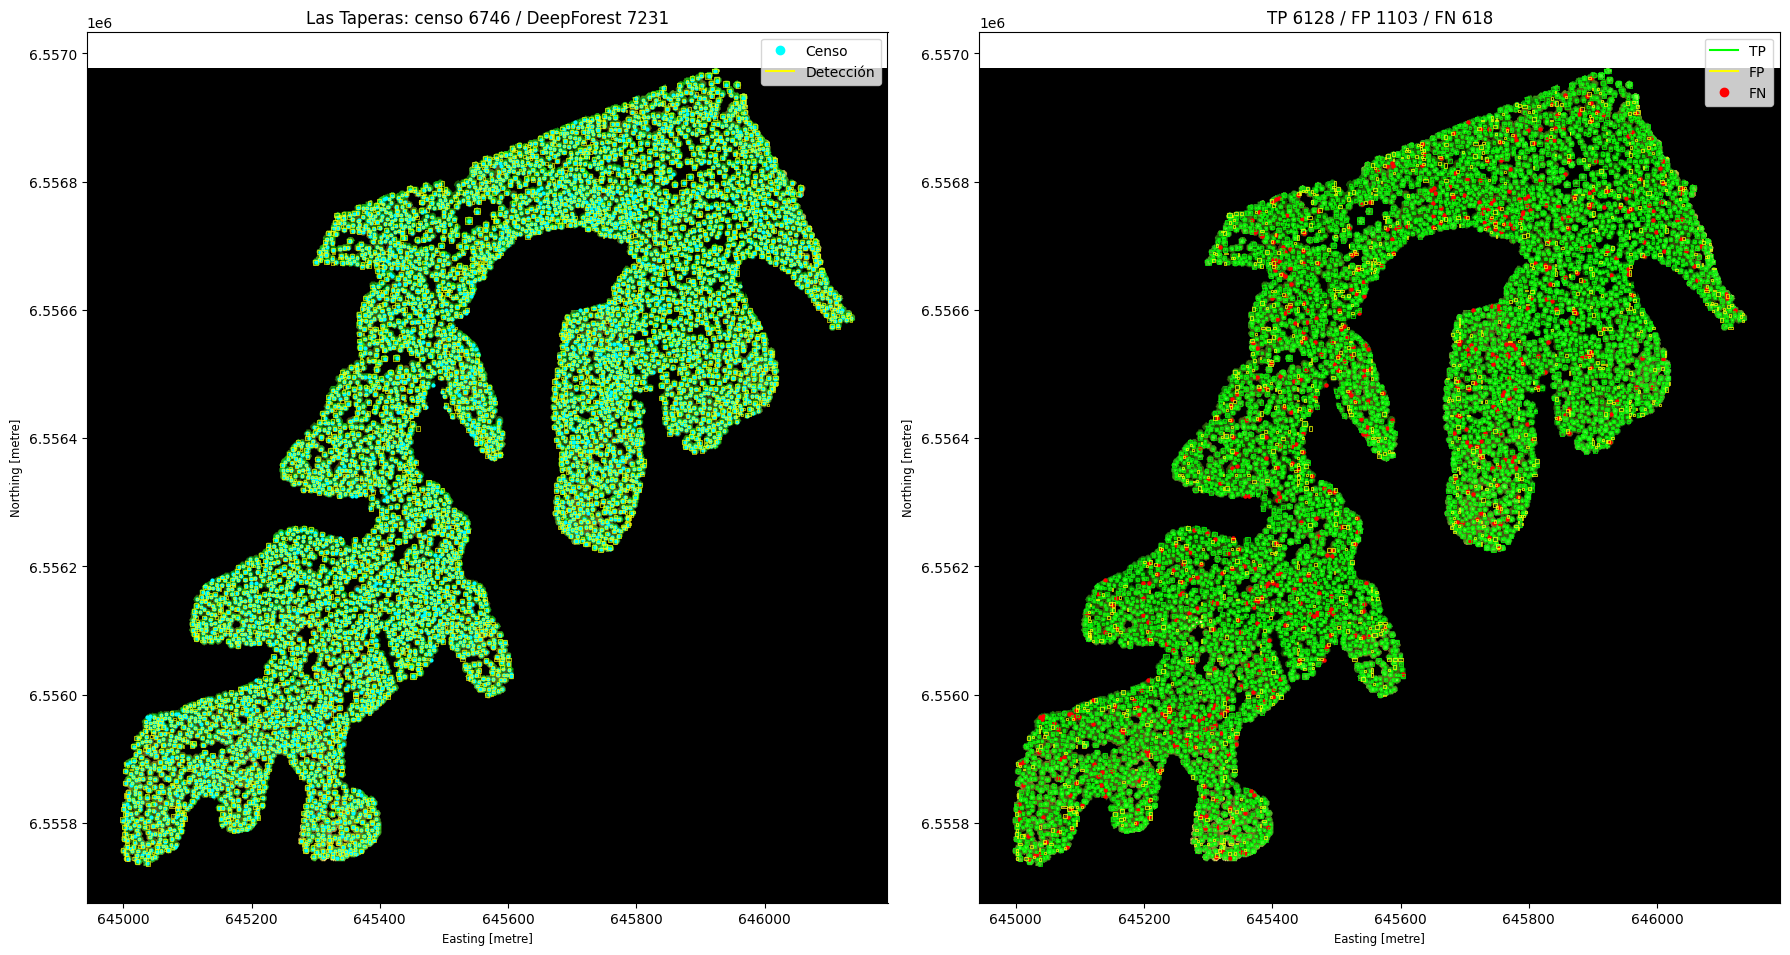

Mapa: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las_Taperas_DeepForest/DeepForest_mapa_evaluacion.png


In [ ]:
# Separar las detecciones correctas, las adicionales y los árboles omitidos.
ids_ref={r['id_punto'] for r in coincidencias}
ids_pred={r['id_pred'] for r in coincidencias}
fn=ref.loc[~ref.id_punto.isin(ids_ref)]
fp=pred_eval.loc[~pred_eval.id_pred.isin(ids_pred)]
tp=pred_eval.loc[pred_eval.id_pred.isin(ids_pred)]
with rasterio.open(PREPARADA) as src:
    escala=max(1,int(np.ceil(max(src.width,src.height)/2000)))
    img=src.read([1,2,3],out_shape=(3,max(1,src.height//escala),max(1,src.width//escala)),resampling=Resampling.nearest)
    rgb=np.moveaxis(img,0,-1)
    b=src.bounds
# Comparar censo/detecciones y mostrar los errores de detección.
fig,axes=plt.subplots(1,2,figsize=(18,10))
for ax in axes:
    ax.imshow(rgb,extent=(b.left,b.right,b.bottom,b.top),origin='upper')
    ax.set_aspect('equal')
if len(pred_eval):pred_eval.boundary.plot(ax=axes[0],color='yellow',linewidth=.45)
ref.plot(ax=axes[0],color='cyan',markersize=4)
axes[0].set_title(f'{SITIO}: censo {NR} / DeepForest {NP}')
axes[0].legend(handles=[Line2D([0],[0],marker='o',linestyle='',color='cyan',label='Censo'),Line2D([0],[0],color='yellow',label='Detección')])
if len(tp):tp.boundary.plot(ax=axes[1],color='lime',linewidth=.5)
if len(fp):fp.boundary.plot(ax=axes[1],color='yellow',linewidth=.5)
if len(fn):fn.plot(ax=axes[1],color='red',markersize=5)
axes[1].set_title(f'TP {TP} / FP {FP} / FN {FN}')
axes[1].legend(handles=[Line2D([0],[0],color='lime',label='TP'),Line2D([0],[0],color='yellow',label='FP'),Line2D([0],[0],marker='o',linestyle='',color='red',label='FN')])
# Zoom a la zona de evaluación, no a toda la extensión de la ortofoto.
x0,y0,x1,y1=ref.total_bounds
mx=(x1-x0)*.05;my=(y1-y0)*.05
for ax in axes:
    ax.set_xlim(x0-mx,x1+mx);ax.set_ylim(y0-my,y1+my)
fig.tight_layout()
fig.savefig(SALIDA/'DeepForest_mapa_evaluacion.png',dpi=250,bbox_inches='tight')
plt.show()
plt.close(fig)
print('Mapa:',SALIDA/'DeepForest_mapa_evaluacion.png')

En el establecimiento Las Taperas, el modelo DeepForest fue evaluado mediante la detección individual de árboles sobre una ortofoto y su posterior correspondencia espacial con los registros censales. La evaluación se realizó sobre una superficie operativa aproximada de 45,22 hectáreas, delimitada a partir de áreas de influencia de 6 metros alrededor de los puntos censados y restringida a la cobertura válida de la imagen. De los 6.759 árboles del censo de referencia, 6.746 resultaron evaluables. El modelo generó 7.231 detecciones, de las cuales 6.128 correspondieron a verdaderos positivos y 1.103 a falsos positivos, mientras que 618 árboles censados no fueron detectados.

A partir de estos resultados, se obtuvo una precisión del 84,75 %, un recall del 90,84 % y un F1-score del 87,69 %. En cuanto al conteo, el modelo presentó una sobreestimación neta de 485 árboles, equivalente a un error porcentual del +7,19 %.

Estos resultados evidencian un buen desempeño en la detección individual de árboles, particularmente en términos de recall, aunque con una tendencia a sobreestimar el número total de individuos. Si bien el modelo logró identificar una proporción elevada de los árboles censados, también generó detecciones sin correspondencia, lo que afectó la precisión y el conteo final. Asimismo, los resultados deben interpretarse considerando que la superficie evaluada corresponde a una delimitación operativa derivada del propio censo, que puede influir en la cantidad de falsos positivos registrados.

## 4. Mask R-CNN

### Configuración

In [ ]:
MODELO = 'Mask_RCNN'
SALIDA = PROYECTO / 'PruebaFinal' / 'resultados' / SITIO / MODELO
SALIDA.mkdir(parents=True, exist_ok=True)
MASCARA = MASCARA_COMUN
PREPARADA = SALIDA / 'ortofoto_uint8_global.tif'
PESOS = PROYECTO / 'MASK-R-CNN' / 'runs' / 'mask_rcnn_R50_FPN_torchvision' / 'maskrcnn_final.pth'

TILE = 640
STRIDE = 512
CONF = 0.20
MASK_THR = 0.50
MIN_PIX = 15
MIN_VALID_FRAC = 0.10
NMS_IOU = 0.50

print('Sitio:', SITIO, '| Modelo:', MODELO)
print('Imagen:', RASTER)
print('Censo:', CENSO)
print('Salida:', SALIDA)

Sitio: Las Taperas | Modelo: Mask_RCNN
Imagen: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Las_Taperas_Pot2_Clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/datos/Censo_LasTaperas_002_parcelas_41_42_43_44_45.shp
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las Taperas/Mask_RCNN


### Inferencia y eliminación de duplicados

In [ ]:
# Mantener el raster original si ya tiene tres bandas uint8.
RASTER_MODELO = PREPARADA
with rasterio.open(RASTER) as src:
    is8 = all(dtype == 'uint8' for dtype in src.dtypes[:3])

if is8:
    RASTER_MODELO = RASTER
    print('Raster original uint8.')
else:
    with rasterio.open(RASTER) as src:
        arr = src.read([1, 2, 3]).astype('float32')
        if src.nodata is not None:
            valid = np.all(~np.isclose(arr, src.nodata), axis=0)
        else:
            valid = src.read_masks(1) > 0
        vv = arr[:, valid]
        assert vv.size > 0, 'No hay píxeles válidos.'
        p2, p98 = np.percentile(vv, [2, 98])
        assert np.isfinite(p2) and np.isfinite(p98) and p98 > p2, 'Percentiles inválidos.'
        salida8 = (np.clip((arr - p2) / (p98 - p2), 0, 1) * 255).astype('uint8')
        salida8[:, ~valid] = 0
        perfil = src.profile.copy()
        perfil.update(driver='GTiff', count=3, dtype='uint8', nodata=0, compress='deflate')
        with rasterio.open(RASTER_MODELO, 'w', **perfil) as dst:
            dst.write(salida8)
        del arr, vv, valid, salida8
    print('RGB preparado:', RASTER_MODELO, '| P2:', p2, '| P98:', p98)

import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
modelo = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None)
in_feat = modelo.roi_heads.box_predictor.cls_score.in_features
modelo.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
in_feat = modelo.roi_heads.mask_predictor.conv5_mask.in_channels
modelo.roi_heads.mask_predictor = MaskRCNNPredictor(in_feat, 256, 2)
estado = torch.load(PESOS, map_location='cpu', weights_only=True)
modelo.load_state_dict(estado, strict=True)
modelo.to(DEVICE).eval()
print('Pesos:', PESOS, '| Dispositivo:', DEVICE)

# Incluir una última tesela alineada al borde cuando el tamaño no es múltiplo del paso.
def posiciones(total, tam, paso):
    if total <= tam:
        return [0]
    arr = list(range(0, total - tam + 1, paso))
    if arr[-1] != total - tam:
        arr.append(total - tam)
    return sorted(set(arr))

registros = []
ntile = 0
with rasterio.open(RASTER_MODELO) as src:
    assert src.crs == censo_eval.crs, 'CRS raster/censo distintos.'
    xs = posiciones(src.width, TILE, STRIDE)
    ys = posiciones(src.height, TILE, STRIDE)
    for y in tqdm(ys, desc='Filas Mask R-CNN'):
        for x in xs:
            win = Window(x, y, min(TILE, src.width - x), min(TILE, src.height - y))
            a = src.read([1, 2, 3], window=win, masked=True)
            invalida = np.ma.getmaskarray(a).any(axis=0) | np.all(a.filled(0) == 0, axis=0)
            if (~invalida).mean() < MIN_VALID_FRAC:
                continue
            rgb = np.moveaxis(a.filled(0).astype(np.uint8), 0, -1)
            tens = torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1).float().div(255).to(DEVICE)
            with torch.inference_mode():
                out = modelo([tens])[0]
            ntile += 1
            tr = src.window_transform(win)
            for score, label, mask in zip(out['scores'].cpu().numpy(),
                                          out['labels'].cpu().numpy(),
                                          out['masks'].cpu().numpy()):
                if int(label) != 1 or float(score) < CONF:
                    continue
                binary = mask[0] >= MASK_THR
                binary[invalida] = False
                if int(binary.sum()) < MIN_PIX:
                    continue
                for geom, val in shapes(binary.astype('uint8'), mask=binary, transform=tr):
                    if val != 1:
                        continue
                    pol = shape(geom)
                    if not pol.is_empty and pol.area > 0:
                        registros.append({'score': float(score), 'geometry': pol})
            del tens, out

print('Teselas procesadas:', ntile, '| Propuestas crudas:', len(registros))
pred_brutas = gpd.GeoDataFrame(registros, columns=['score', 'geometry'],
                               geometry='geometry', crs=censo_eval.crs)
pred_brutas = pred_brutas.sort_values('score', ascending=False).reset_index(drop=True)

# NMS: conservar la detección de mayor confianza en cada solapamiento alto.
if len(pred_brutas):
    idx = pred_brutas.sindex
    guardados, eliminados = [], set()
    for i in tqdm(range(len(pred_brutas)), desc='NMS'):
        if i in eliminados:
            continue
        guardados.append(i)
        g = pred_brutas.geometry.iloc[i]
        for j in idx.query(g, predicate='intersects'):
            j = int(j)
            if j <= i or j in eliminados:
                continue
            h = pred_brutas.geometry.iloc[j]
            union = g.union(h).area
            if union > 0 and g.intersection(h).area / union >= NMS_IOU:
                eliminados.add(j)
    pred_unicas = pred_brutas.iloc[guardados].copy().reset_index(drop=True)
else:
    pred_unicas = pred_brutas.copy()
print('Detecciones únicas antes de la máscara:', len(pred_unicas))


RGB preparado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las Taperas/Mask_RCNN/ortofoto_uint8_global.tif | P2: 0.01196579335257411 | P98: 0.05137830846011637
Pesos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/MASK-R-CNN/runs/mask_rcnn_R50_FPN_torchvision/maskrcnn_final.pth | Dispositivo: cuda


Filas Mask R-CNN:   0%|          | 0/22 [00:00<?, ?it/s]

Teselas procesadas: 162 | Propuestas crudas: 21415


NMS:   0%|          | 0/21415 [00:00<?, ?it/s]

Detecciones únicas antes de la máscara: 15563


### Evaluación

In [ ]:
ref, pred_eval, coincidencias, metricas = evaluar_detecciones(pred_unicas, censo_eval, MASCARA)
NR, NP = metricas['censo_evaluable'], metricas['detecciones']
TP, FP, FN = metricas['TP'], metricas['FP'], metricas['FN']
resumen = pd.DataFrame([dict(sitio=SITIO, modelo='Mask R-CNN R50-FPN', **metricas)])
resumen_mask_rcnn = resumen.copy()
display(resumen.round(4))
resumen.to_csv(SALIDA / 'Mask_RCNN_metricas.csv', index=False)
pd.DataFrame(coincidencias, columns=['id_punto','id_pred','distancia_m']).to_csv(SALIDA / 'Mask_RCNN_coincidencias.csv', index=False)
ref.to_file(SALIDA / 'censo_evaluable.gpkg', driver='GPKG')
if len(pred_eval):
    pred_eval.to_file(SALIDA / 'detecciones_evaluables.gpkg', driver='GPKG')


,sitio,modelo,censo_total,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct
0,Las Taperas,Mask R-CNN R50-FPN,6759,6746,6721,4427,2294,2319,0.6587,0.6562,0.6575,-0.3706,0.3706


### Visualización

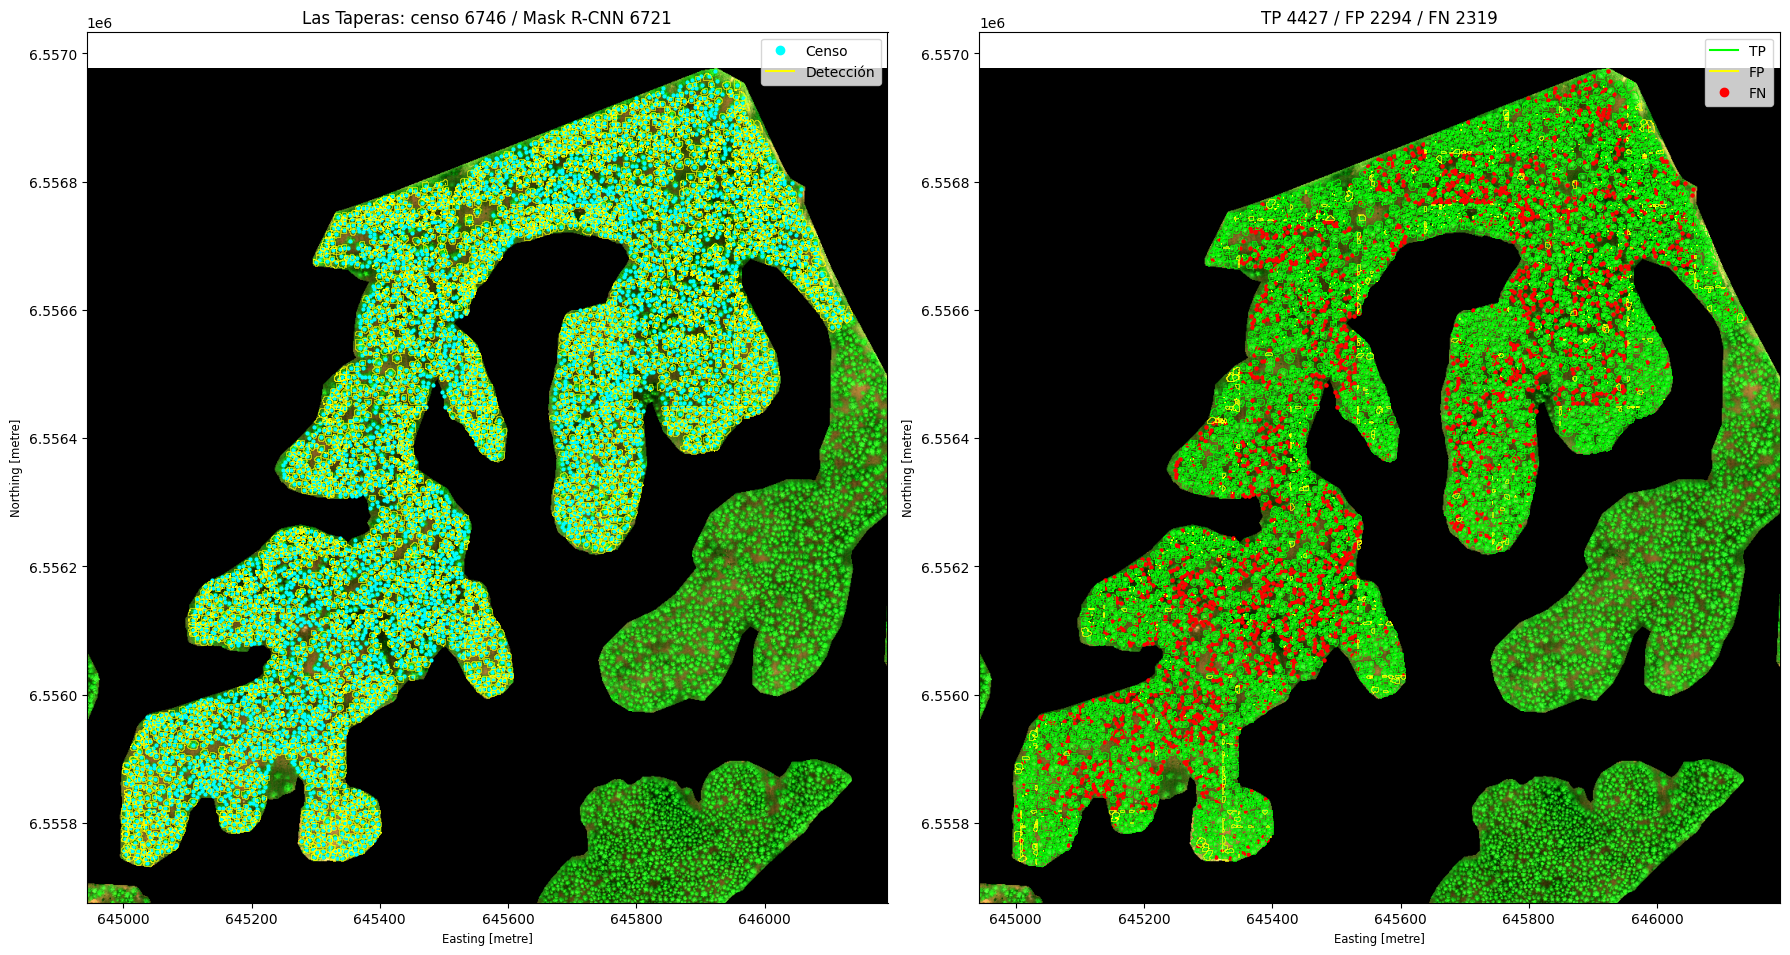

Mapa: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/PruebaFinal/resultados/Las Taperas/Mask_RCNN/Mask_RCNN_mapa_evaluacion.png


In [ ]:
# Separar las detecciones correctas, las adicionales y los árboles omitidos.
ids_ref={r['id_punto'] for r in coincidencias}
ids_pred={r['id_pred'] for r in coincidencias}
fn=ref.loc[~ref.id_punto.isin(ids_ref)]
fp=pred_eval.loc[~pred_eval.id_pred.isin(ids_pred)]
tp=pred_eval.loc[pred_eval.id_pred.isin(ids_pred)]
with rasterio.open(RASTER_MODELO) as src:
    escala=max(1,int(np.ceil(max(src.width,src.height)/2000)))
    img=src.read([1,2,3],out_shape=(3,max(1,src.height//escala),max(1,src.width//escala)),resampling=Resampling.nearest)
    rgb=np.moveaxis(img,0,-1)
    b=src.bounds
# Comparar censo/detecciones y mostrar los errores de detección.
fig,axes=plt.subplots(1,2,figsize=(18,10))
for ax in axes:
    ax.imshow(rgb,extent=(b.left,b.right,b.bottom,b.top),origin='upper')
    ax.set_aspect('equal')
if len(pred_eval):pred_eval.boundary.plot(ax=axes[0],color='yellow',linewidth=.45)
ref.plot(ax=axes[0],color='cyan',markersize=4)
axes[0].set_title(f'{SITIO}: censo {NR} / Mask R-CNN {NP}')
axes[0].legend(handles=[Line2D([0],[0],marker='o',linestyle='',color='cyan',label='Censo'),Line2D([0],[0],color='yellow',label='Detección')])
if len(tp):tp.boundary.plot(ax=axes[1],color='lime',linewidth=.5)
if len(fp):fp.boundary.plot(ax=axes[1],color='yellow',linewidth=.5)
if len(fn):fn.plot(ax=axes[1],color='red',markersize=5)
axes[1].set_title(f'TP {TP} / FP {FP} / FN {FN}')
axes[1].legend(handles=[Line2D([0],[0],color='lime',label='TP'),Line2D([0],[0],color='yellow',label='FP'),Line2D([0],[0],marker='o',linestyle='',color='red',label='FN')])
# Zoom a la zona de evaluación, no a toda la extensión de la ortofoto.
x0,y0,x1,y1=ref.total_bounds
mx=(x1-x0)*.05;my=(y1-y0)*.05
for ax in axes:
    ax.set_xlim(x0-mx,x1+mx);ax.set_ylim(y0-my,y1+my)
fig.tight_layout()
fig.savefig(SALIDA/'Mask_RCNN_mapa_evaluacion.png',dpi=250,bbox_inches='tight')
plt.show()
plt.close(fig)
print('Mapa:',SALIDA/'Mask_RCNN_mapa_evaluacion.png')


En el establecimiento Las Taperas, el modelo Mask R-CNN con arquitectura ResNet-50 y Feature Pyramid Network (R50-FPN) fue evaluado mediante la detección y segmentación de copas individuales sobre una ortofoto y su posterior correspondencia espacial con los registros censales. La evaluación se realizó sobre una superficie operativa aproximada de 45,22 hectáreas, delimitada a partir de áreas de influencia de 6 metros alrededor de los puntos censados y restringida a la cobertura válida de la imagen. De los 6.759 árboles del censo de referencia, 6.746 resultaron evaluables. El modelo generó 6.721 detecciones, de las cuales 4.427 correspondieron a verdaderos positivos y 2.294 a falsos positivos, mientras que 2.319 árboles censados no fueron detectados.

A partir de estos resultados, se obtuvo una precisión del 65,87 %, un recall del 65,62 % y un F1-score del 65,75 %. En cuanto al conteo, el modelo presentó una subestimación neta de 25 árboles, equivalente a un error porcentual del −0,37 %.

Estos resultados evidencian un desempeño moderado en la identificación individual de árboles, con valores similares de precisión y recall. Si bien el número total de detecciones fue muy cercano al censo, la presencia de 2.294 falsos positivos y 2.319 falsos negativos demuestra que el reducido error de conteo se debe a una compensación entre detecciones sin correspondencia y árboles omitidos, y no necesariamente a una identificación individual correcta. Asimismo, los resultados deben interpretarse considerando que la superficie evaluada corresponde a una delimitación operativa derivada del propio censo, que puede influir en la cantidad de falsos positivos registrados.

## 5. Comparación final

In [ ]:
columnas = ['sitio','modelo','censo_evaluable','detecciones','TP','FP','FN','precision','recall','F1','error_conteo_pct']
comparacion = pd.concat([resumen_deepforest, resumen_mask_rcnn], ignore_index=True)
display(comparacion[columnas].round(4))
comparacion.to_csv(SALIDA_COMUN / 'comparacion_modelos.csv', index=False)

,sitio,modelo,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct
0,Las Taperas,DeepForest,6746,7231,6128,1103,618,0.8475,0.9084,0.8769,7.1894
1,Las Taperas,Mask R-CNN R50-FPN,6746,6721,4427,2294,2319,0.6587,0.6562,0.6575,-0.3706
